<a href="https://colab.research.google.com/github/192465049simats-dev/MLA0204/blob/main/Practice_Problem_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset:
     Outlook Temperature Humidity    Wind Target
0      sunny         hot     high    weak     no
1      sunny         hot     high  strong     no
2   overcast         hot     high    weak    yes
3      rainy        mild     high    weak    yes
4      rainy        cool   normal    weak    yes
5      rainy        cool   normal  strong     no
6   overcast        cool   normal  strong    yes
7      sunny        mild     high    weak     no
8      sunny        cool   normal    weak    yes
9      rainy        mild   normal    weak    yes
10     sunny        mild   normal  strong    yes
11  overcast        mild     high  strong    yes
12  overcast         hot   normal    weak    yes
13     rainy        mild     high  strong     no

Information Gain:
Outlook = 0.2467
Temperature = 0.0292
Humidity = 0.1518
Wind = 0.0481

New Sample:
   Outlook_overcast  Outlook_rainy  Outlook_sunny  Temperature_cool  \
0             False          False           True              True   

   Temperat

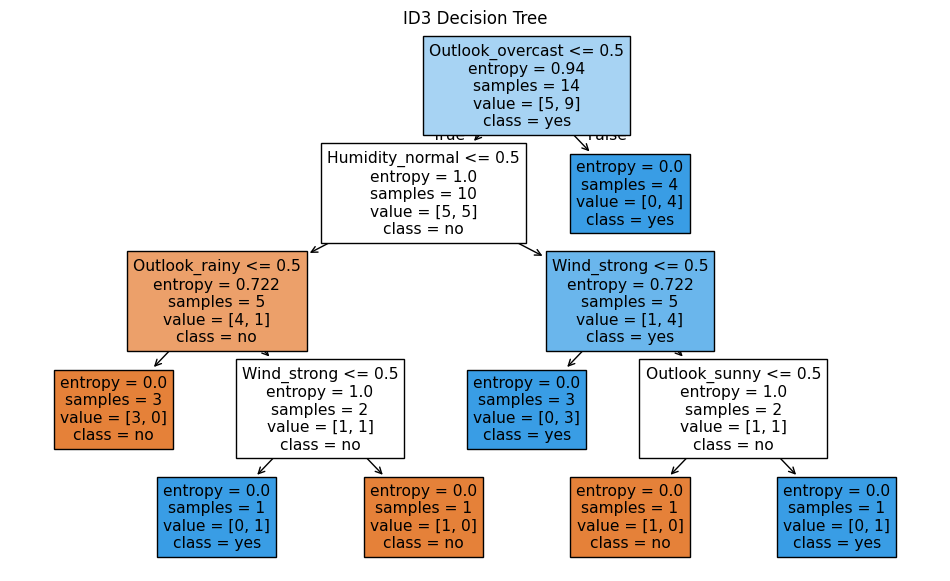

In [2]:
import pandas as pd
import math
from collections import Counter
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

# Programmatically creating the Play Tennis dataset to avoid FileNotFoundError
tennis_data = {
    'Outlook': ['sunny', 'sunny', 'overcast', 'rainy', 'rainy', 'rainy', 'overcast', 'sunny', 'sunny', 'rainy', 'sunny', 'overcast', 'overcast', 'rainy'],
    'Temperature': ['hot', 'hot', 'hot', 'mild', 'cool', 'cool', 'cool', 'mild', 'cool', 'mild', 'mild', 'mild', 'hot', 'mild'],
    'Humidity': ['high', 'high', 'high', 'high', 'normal', 'normal', 'normal', 'high', 'normal', 'normal', 'normal', 'high', 'normal', 'high'],
    'Wind': ['weak', 'strong', 'weak', 'weak', 'weak', 'strong', 'strong', 'weak', 'weak', 'weak', 'strong', 'strong', 'weak', 'strong'],
    'Target': ['no', 'no', 'yes', 'yes', 'yes', 'no', 'yes', 'no', 'yes', 'yes', 'yes', 'yes', 'yes', 'no']
}

data = pd.DataFrame(tennis_data)

def entropy(target):
    values = Counter(target)
    total = len(target)
    ent = 0

    for count in values.values():
        p = count / total
        ent -= p * math.log2(p)

    return ent

def information_gain(data, attribute, target):
    total_entropy = entropy(data[target])
    weighted_entropy = 0

    for value in data[attribute].unique():
        subset = data[data[attribute] == value]
        weighted_entropy += (len(subset) / len(data)) * entropy(subset[target])

    return total_entropy - weighted_entropy

target = "Target"

print("Dataset:")
print(data)

print("\nInformation Gain:")

for column in data.columns:
    if column != target:
        gain = information_gain(data, column, target)
        print(column, "=", round(gain, 4))

X = data.drop(target, axis=1)
y = data[target]

X = pd.get_dummies(X)

model = DecisionTreeClassifier(
    criterion="entropy",
    random_state=42
)

model.fit(X, y)

new_sample = pd.DataFrame({
    "Outlook": ["sunny"],
    "Temperature": ["cool"],
    "Humidity": ["high"],
    "Wind": ["strong"]
})

new_sample = pd.get_dummies(new_sample)
new_sample = new_sample.reindex(columns=X.columns, fill_value=False)

prediction = model.predict(new_sample)

print("\nNew Sample:")
print(new_sample)

print("\nPredicted Class:", prediction[0])

accuracy = accuracy_score(y, model.predict(X))

print("\nAccuracy:", round(accuracy * 100, 2), "%")

plt.figure(figsize=(12, 7))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=model.classes_,
    filled=True
)

plt.title("ID3 Decision Tree")
plt.show()